In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
customers_dataset = pd.read_excel(r'C:\Users\weka\Desktop\Brazilian E-Commerce Public Dataset by Olist\excel files\olist_customers_dataset.xlsx')

geolocation_dataset = pd.read_excel(r'C:\Users\weka\Desktop\Brazilian E-Commerce Public Dataset by Olist\excel files\olist_geolocation_dataset.xlsx')

order_items_dataset = pd.read_excel(r'C:\Users\weka\Desktop\Brazilian E-Commerce Public Dataset by Olist\excel files\olist_order_items_dataset.xlsx')

order_payments_dataset=pd.read_excel(r'C:\Users\weka\Desktop\Brazilian E-Commerce Public Dataset by Olist\excel files\olist_order_payments_dataset.xlsx')

order_reviews_dataset = pd.read_excel(r'C:\Users\weka\Desktop\Brazilian E-Commerce Public Dataset by Olist\excel files\olist_order_reviews_dataset.xlsx')

orders_dataset = pd.read_excel(r'C:\Users\weka\Desktop\Brazilian E-Commerce Public Dataset by Olist\excel files\olist_orders_dataset.xlsx')

products_dataset = pd.read_excel(r'C:\Users\weka\Desktop\Brazilian E-Commerce Public Dataset by Olist\excel files\olist_products_dataset.xlsx')

sellers_dataset = pd.read_excel(r'C:\Users\weka\Desktop\Brazilian E-Commerce Public Dataset by Olist\excel files\olist_sellers_dataset.xlsx')


In [3]:
customers_dataset.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [4]:
customers_dataset.isnull().sum()

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [5]:
customers_dataset.dtypes

customer_id                 object
customer_unique_id          object
customer_zip_code_prefix     int64
customer_city               object
customer_state              object
dtype: object

In [6]:
customers_dataset['customer_zip_code_prefix'] = customers_dataset['customer_zip_code_prefix'].astype('str')

In [7]:
customers_dataset.dtypes

customer_id                 object
customer_unique_id          object
customer_zip_code_prefix    object
customer_city               object
customer_state              object
dtype: object

In [8]:
customers_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  object
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: object(5)
memory usage: 3.8+ MB


In [9]:
customers_dataset.shape

(99441, 5)

In [10]:
customers_dataset['customer_id'] .nunique()

99441

In [11]:
customers_dataset['customer_id'] .is_unique

True

In [12]:
customers_dataset['customer_unique_id'].is_unique

False

In [13]:
customers_dataset['customer_unique_id'].nunique()

96096

In [14]:
geolocation_dataset.head(5)

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [15]:
geolocation_dataset.dtypes

geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                object
geolocation_state               object
dtype: object

In [16]:
geolocation_dataset.isnull().sum()

geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_lng                0
geolocation_city               0
geolocation_state              0
dtype: int64

In [17]:
geolocation_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  object 
 4   geolocation_state            1000163 non-null  object 
dtypes: float64(2), int64(1), object(2)
memory usage: 38.2+ MB


In [18]:
geolocation_dataset.shape

(1000163, 5)

In [19]:
from unidecode import unidecode

geolocation_dataset['geolocation_city'] = geolocation_dataset['geolocation_city'].apply(unidecode)


In [20]:
geolocation_dataset['geolocation_city'].head(10)

0      sao paulo
1      sao paulo
2      sao paulo
3      sao paulo
4      sao paulo
5    s'PSo paulo
6      sao paulo
7      sao paulo
8      sao paulo
9      sao paulo
Name: geolocation_city, dtype: object

In [21]:
geolocation_dataset['geolocation_city'] = geolocation_dataset['geolocation_city'].str.lower()
geolocation_dataset['geolocation_city'] = geolocation_dataset['geolocation_city'].str.strip()

In [22]:
geolocation_dataset['geolocation_city'] = geolocation_dataset['geolocation_city'] .replace("s'pso paulo" , 'sao paulo')
geolocation_dataset['geolocation_city'] = geolocation_dataset['geolocation_city'].str.replace("'" , 'o')
geolocation_dataset['geolocation_city'] = geolocation_dataset['geolocation_city'].str.replace("/" , 'o')
geolocation_dataset['geolocation_city'] = geolocation_dataset['geolocation_city'].str.replace("?" , 'o')

In [23]:
geolocation_dataset['geolocation_city'] . value_counts()

geolocation_city
sao paulo           160718
rio de janeiro       62151
belo horizonte       27805
curitiba             16593
porto alegre         13521
                     ...  
jundio,                  1
fonseca                  1
senhora do carmo         1
barra feliz              1
juoz de fora             1
Name: count, Length: 8009, dtype: int64

In [24]:
geolocation_dataset['geolocation_city'] . unique()

array(['sao paulo', 'sao bernardo do campo', 'jundiao', ..., 'ciroaco',
       'estaossopso', 'vila locongaro'], dtype=object)

In [25]:
order_items_dataset.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:00,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:00,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:00,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:00,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:00,199.90,18.14


In [26]:
order_items_dataset.dtypes

order_id                       object
order_item_id                   int64
product_id                     object
seller_id                      object
shipping_limit_date    datetime64[ns]
price                         float64
freight_value                 float64
dtype: object

In [27]:
order_items_dataset['shipping_limit_date'] =pd.to_datetime (order_items_dataset['shipping_limit_date']).dt.normalize()

In [28]:
order_items_dataset.dtypes

order_id                       object
order_item_id                   int64
product_id                     object
seller_id                      object
shipping_limit_date    datetime64[ns]
price                         float64
freight_value                 float64
dtype: object

In [29]:
order_items_dataset.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13,199.90,18.14


In [30]:
order_items_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   order_id             112650 non-null  object        
 1   order_item_id        112650 non-null  int64         
 2   product_id           112650 non-null  object        
 3   seller_id            112650 non-null  object        
 4   shipping_limit_date  112650 non-null  datetime64[ns]
 5   price                112650 non-null  float64       
 6   freight_value        112650 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(1), object(3)
memory usage: 6.0+ MB


In [31]:
order_items_dataset.shape

(112650, 7)

In [32]:
order_items_dataset.describe()

,order_item_id,shipping_limit_date,price,freight_value
count,112650.000000,112650,112650.000000,112650.000000
mean,1.197834,2018-01-07 02:28:41.480692480,120.653739,19.990320
min,1.000000,2016-09-19 00:00:00,0.850000,0.000000
25%,1.000000,2017-09-20 00:00:00,39.900000,13.080000
50%,1.000000,2018-01-26 00:00:00,74.990000,16.260000
75%,1.000000,2018-05-10 00:00:00,134.900000,21.150000
max,21.000000,2020-04-09 00:00:00,6735.000000,409.680000
std,0.705124,NaN,183.633928,15.806405


In [33]:
order_items_dataset.isnull().sum()

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

In [34]:
order_items_dataset['order_id'].is_unique

False

In [35]:
order_items_dataset['product_id'].is_unique

False

In [36]:
order_payments_dataset . head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [37]:
order_payments_dataset.isnull().sum()

order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

In [38]:
order_payments_dataset .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB


In [39]:
order_payments_dataset.describe()

,payment_sequential,payment_installments,payment_value
count,103886.000000,103886.000000,103886.000000
mean,1.092679,2.853349,154.100380
std,0.706584,2.687051,217.494064
min,1.000000,0.000000,0.000000
25%,1.000000,1.000000,56.790000
50%,1.000000,1.000000,100.000000
75%,1.000000,4.000000,171.837500
max,29.000000,24.000000,13664.080000


In [40]:
order_payments_dataset['order_id']. is_unique

False

In [41]:
order_reviews_dataset.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabأ©ns lojas lannister adorei comprar pela ...,2018-03-01,2018-03-02 10:26:53


In [42]:
order_reviews_dataset = order_reviews_dataset.drop(columns=['review_comment_title','review_comment_message'])

In [43]:
order_reviews_dataset.head()

,review_id,order_id,review_score,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,2018-01-18,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,2018-03-10,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,2018-02-17,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,2017-04-21,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,2018-03-01,2018-03-02 10:26:53


In [44]:
order_reviews_dataset['review_answer_timestamp']=pd.to_datetime(order_reviews_dataset['review_answer_timestamp']).dt.normalize()

In [45]:
order_reviews_dataset.head()

,review_id,order_id,review_score,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,2018-01-18,2018-01-18
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,2018-03-10,2018-03-11
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,2018-02-17,2018-02-18
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,2017-04-21,2017-04-21
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,2018-03-01,2018-03-02


In [46]:
order_reviews_dataset['order_id'].is_unique

False

In [47]:
orders_dataset.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


In [48]:
orders_dataset['order_purchase_timestamp'] = pd.to_datetime(orders_dataset['order_purchase_timestamp']).dt.normalize() 

orders_dataset['order_approved_at'] = pd.to_datetime(orders_dataset['order_approved_at']).dt.normalize() 

orders_dataset['order_delivered_carrier_date'] = pd.to_datetime(orders_dataset['order_delivered_carrier_date']).dt.normalize() 

orders_dataset['order_delivered_customer_date'] = pd.to_datetime(orders_dataset['order_delivered_customer_date']).dt.normalize() 


In [49]:
orders_dataset.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02,2017-10-02,2017-10-04,2017-10-10,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24,2018-07-26,2018-07-26,2018-08-07,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08,2018-08-08,2018-08-08,2018-08-17,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18,2017-11-18,2017-11-22,2017-12-02,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13,2018-02-13,2018-02-14,2018-02-16,2018-02-26


In [50]:
orders_dataset['customer_id'] . is_unique

True

In [51]:
orders_dataset['order_id'] . is_unique

True

In [52]:
products_dataset.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [53]:
products_dataset. isnull().sum()

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

In [54]:
products_dataset['product_category_name'] = products_dataset['product_category_name'] . fillna('unknown')


In [55]:
products_dataset['product_name_lenght'] = products_dataset['product_name_lenght'] . fillna(products_dataset['product_name_lenght'].median())

In [56]:
products_dataset['product_description_lenght'] = products_dataset['product_description_lenght'] . fillna(
    products_dataset['product_description_lenght'].median())

In [57]:
products_dataset['product_photos_qty'] = products_dataset['product_photos_qty'] . fillna(products_dataset['product_photos_qty'].median())

In [58]:
products_dataset. isnull().sum()

product_id                    0
product_category_name         0
product_name_lenght           0
product_description_lenght    0
product_photos_qty            0
product_weight_g              2
product_length_cm             2
product_height_cm             2
product_width_cm              2
dtype: int64

In [59]:
products_dataset['product_id'].is_unique

True

In [60]:
products_dataset = products_dataset.dropna(subset=['product_weight_g'])
products_dataset = products_dataset.dropna(subset=['product_length_cm'])
products_dataset = products_dataset.dropna(subset=['product_height_cm'])
products_dataset = products_dataset.dropna(subset=['product_width_cm'])

In [61]:
products_dataset. isnull().sum()

product_id                    0
product_category_name         0
product_name_lenght           0
product_description_lenght    0
product_photos_qty            0
product_weight_g              0
product_length_cm             0
product_height_cm             0
product_width_cm              0
dtype: int64

In [62]:
products_dataset.describe().round(2)

,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32949.00,32949.00,32949.00,32949.00,32949.00,32949.00,32949.00
mean,48.52,768.23,2.17,2276.47,30.82,16.94,23.20
std,10.16,629.68,1.73,4282.04,16.91,13.64,12.08
min,5.00,4.00,1.00,0.00,7.00,2.00,6.00
25%,42.00,344.00,1.00,300.00,18.00,8.00,15.00
50%,51.00,595.00,1.00,700.00,25.00,13.00,20.00
75%,57.00,961.00,3.00,1900.00,38.00,21.00,30.00
max,76.00,3992.00,20.00,40425.00,105.00,105.00,118.00


In [63]:
sellers_dataset.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [64]:
sellers_dataset['seller_id'].is_unique

True

In [65]:
customer = customers_dataset.merge(orders_dataset, on='customer_id', how='inner')

order = orders_dataset.merge(order_items_dataset, on='order_id', how='inner')
order = order.merge(order_payments_dataset, on='order_id', how='left')
order = order.merge(order_reviews_dataset, on='order_id', how='left')

product = products_dataset.merge(order_items_dataset, on='product_id', how='inner')

In [66]:
total_price = order_items_dataset['price'].sum()
average_price = order_items_dataset['price'].mean()
median_price = order_items_dataset['price'].median()

min_price = order_items_dataset['price'].min()
max_price = order_items_dataset['price'].max()
q1_price = order_items_dataset['price'].quantile(0.25)
q3_price = order_items_dataset['price'].quantile(0.75)
std_price = order_items_dataset['price'].std()

IQR = q3_price - q1_price
lower_bound = q1_price - (1.5 * IQR)
upper_bound = q3_price + (1.5 * IQR)

outliers = order_items_dataset[(order_items_dataset['price'] < lower_bound) |
                               (order_items_dataset['price'] > upper_bound)]

outliers_count = len(outliers)
outliers_percentage = (outliers_count / len(order_items_dataset)) *100


print(f'total price :{total_price:.2f}$')
print(f'average price :{average_price:.2f}$')
print(f'median price :{median_price:.2f}$')
print(f'min price :{min_price:.2f}$')
print(f'max price :{max_price:.2f}$')
print(f'q1 price :{q1_price:.2f}')
print(f'q3 price :{q3_price:.2f}')
print(f'standered deviation price :{std_price:.2f}')
print(f'IQR :{IQR:.2f}')
print(f'lower bound  :{lower_bound :.2f}')
print(f'upper bound :{upper_bound:.2f}')
print(f'outliers count :{outliers_count}')
print(f'outliers percentage :{outliers_percentage:.2f}%')


total price :13591643.70$
average price :120.65$
median price :74.99$
min price :0.85$
max price :6735.00$
q1 price :39.90
q3 price :134.90
standered deviation price :183.63
IQR :95.00
lower bound  :-102.60
upper bound :277.40
outliers count :8427
outliers percentage :7.48%


In [67]:
stats = order_items_dataset['freight_value'] . agg(['sum' , 'mean' , 'median' , 'min' , 'max' ,'std'])

Q1 , Q3 = order_items_dataset['freight_value'] . quantile([0.25 , 0.75])

IQR = Q3 - Q1

lower_bound , upper_bound = Q1-(1.5 * IQR) , Q3+(1.5 * IQR)

outliers = order_items_dataset[(order_items_dataset['freight_value'] < lower_bound) |
                               (order_items_dataset['freight_value'] > upper_bound)]

outliers_count = len(outliers)
outliers_percentage = (outliers_count / len(order_items_dataset)) *100


print(stats.round(2))
print(f'Q1 : {Q1:.2f} , Q3 : {Q3:.2f}')
print(f'lower_bound : {lower_bound:.2f}, upper_bound : {upper_bound:.2f}')
print(f'outliers_count : {outliers_count}')
print(f'outliers_percentage : {outliers_percentage:.2f}%')


sum       2251909.54
mean           19.99
median         16.26
min             0.00
max           409.68
std            15.81
Name: freight_value, dtype: float64
Q1 : 13.08 , Q3 : 21.15
lower_bound : 0.98, upper_bound : 33.25
outliers_count : 12134
outliers_percentage : 10.77%


In [68]:
stats = order_payments_dataset['payment_value'] .agg(['sum' , 'mean' , 'median' , 'min' , 'max' ,'std'])

Q1 , Q3 = order_payments_dataset['payment_value'] . quantile([0.25 , 0.75])

IQR = Q3 -Q1

lower_bound , upper_bound = Q1-(1.5 * IQR) , Q3+(1.5 * IQR)

outliers = order_payments_dataset[(order_payments_dataset['payment_value'] < lower_bound) |
            (order_payments_dataset['payment_value'] > upper_bound )]

outliers_count = len(outliers)
outliers_percentage = (outliers_count / len(order_payments_dataset))*100


print(stats.round(2))
print(f'Q1 : {Q1:.2f} , Q3 : {Q3:.2f}')
print(f'lower_bound : {lower_bound:.2f}, upper_bound : {upper_bound:.2f}')
print(f'outliers_count : {outliers_count}')
print(f'outliers_percentage : {outliers_percentage:.2f}%')
        


sum       16008872.12
mean           154.10
median         100.00
min              0.00
max          13664.08
std            217.49
Name: payment_value, dtype: float64
Q1 : 56.79 , Q3 : 171.84
lower_bound : -115.78, upper_bound : 344.41
outliers_count : 7981
outliers_percentage : 7.68%


In [69]:
stats = order_payments_dataset['payment_installments'] .agg(['sum' , 'mean' , 'median' , 'min' , 'max' ,'std'])

Q1 , Q3 = order_payments_dataset['payment_installments'] . quantile([0.25 , 0.75])

IQR = Q3 -Q1

lower_bound , upper_bound = Q1-(1.5 * IQR) , Q3+(1.5 * IQR)

outliers = order_payments_dataset[(order_payments_dataset['payment_installments'] < lower_bound) |
            (order_payments_dataset['payment_installments'] > upper_bound )]

outliers_count = len(outliers)
outliers_percentage = (outliers_count / len(order_payments_dataset))*100


print(stats.round(2))
print(f'Q1 : {Q1:.2f} , Q3 : {Q3:.2f}')
print(f'lower_bound : {lower_bound:.2f}, upper_bound : {upper_bound:.2f}')
print(f'outliers_count : {outliers_count}')
print(f'outliers_percentage : {outliers_percentage:.2f}%')
        


sum       296423.00
mean           2.85
median         1.00
min            0.00
max           24.00
std            2.69
Name: payment_installments, dtype: float64
Q1 : 1.00 , Q3 : 4.00
lower_bound : -3.50, upper_bound : 8.50
outliers_count : 6313
outliers_percentage : 6.08%


In [70]:
count_customer_city = customers_dataset.groupby('customer_city')['customer_city'].count().sort_values(ascending=False).head(10)
print(count_customer_city)

customer_city
sao paulo                15540
rio de janeiro            6882
belo horizonte            2773
brasilia                  2131
curitiba                  1521
campinas                  1444
porto alegre              1379
salvador                  1245
guarulhos                 1189
sao bernardo do campo      938
Name: customer_city, dtype: int64


In [71]:
count_customer_state = customers_dataset.groupby('customer_state')['customer_state'].count().sort_values(ascending=False).head(10)
print(count_customer_state)

customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
Name: customer_state, dtype: int64


In [72]:
count_geolocation_city = geolocation_dataset.groupby('geolocation_city')['geolocation_city'].count().sort_values(ascending=False).head(10)
print(count_geolocation_city)

geolocation_city
sao paulo                160718
rio de janeiro            62151
belo horizonte            27805
curitiba                  16593
porto alegre              13521
salvador                  11866
guarulhos                 11340
brasilia                  10470
sao bernardo do campo      8112
osasco                     7658
Name: geolocation_city, dtype: int64


In [73]:
count_geolocation_state = geolocation_dataset.groupby('geolocation_state')['geolocation_state'].count().sort_values(ascending=False).head(10)
print(count_geolocation_state)

geolocation_state
SP    404268
MG    126336
RJ    121169
RS     61851
PR     57859
SC     38328
BA     36045
GO     20139
ES     16748
PE     16432
Name: geolocation_state, dtype: int64


In [74]:
count_payment_type = order_payments_dataset.groupby('payment_type')['payment_type'].count().sort_values(ascending=False)
print(count_payment_type)

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: payment_type, dtype: int64


In [75]:
count_review_score = order_reviews_dataset.groupby('review_score')['review_score'].count().sort_values(ascending=False)
print(count_review_score)

review_score
5    57328
4    19142
1    11424
3     8179
2     3151
Name: review_score, dtype: int64


In [76]:
count_order_status = orders_dataset.groupby('order_status')['order_status'].count().sort_values(ascending=False)
print(count_order_status)

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: order_status, dtype: int64


In [77]:
count_product_category_name = products_dataset.groupby('product_category_name')['product_category_name'].count().sort_values(ascending=False) .head(10)
print(count_product_category_name)

product_category_name
cama_mesa_banho           3029
esporte_lazer             2867
moveis_decoracao          2657
beleza_saude              2444
utilidades_domesticas     2335
automotivo                1900
informatica_acessorios    1639
brinquedos                1411
relogios_presentes        1329
telefonia                 1134
Name: product_category_name, dtype: int64


In [78]:
count_seller_city = sellers_dataset.groupby('seller_city')['seller_city'].count().sort_values(ascending=False) .head(10)
print(count_seller_city)

seller_city
sao paulo         694
curitiba          127
rio de janeiro     96
belo horizonte     68
ribeirao preto     52
guarulhos          50
ibitinga           49
santo andre        45
campinas           41
maringa            40
Name: seller_city, dtype: int64


In [79]:
count_seller_state = sellers_dataset.groupby('seller_state')['seller_state'].count().sort_values(ascending=False) .head(10)
print(count_seller_state)

seller_state
SP    1849
PR     349
MG     244
SC     190
RJ     171
RS     129
GO      40
DF      30
ES      23
BA      19
Name: seller_state, dtype: int64


In [80]:
stats_product = product.groupby('product_category_name').agg(
    total_price=('price' , 'sum') , avg_price=('price' , 'mean'),
    total_freight_value=('freight_value' , 'sum') , avg_freight_value=('freight_value' , 'mean')) .sort_values('avg_price' , ascending=False) .head(10)

display(stats_product.round(2))
    

,total_price,avg_price,total_freight_value,avg_freight_value
product_category_name,,,,
pcs,222963.13,1098.34,9836.30,48.45
portateis_casa_forno_e_cafe,47445.71,624.29,2747.86,36.16
eletrodomesticos_2,113317.74,476.12,10600.18,44.54
agro_industria_e_comercio,72530.47,342.12,5843.60,27.56
instrumentos_musicais,191498.88,281.62,18638.49,27.41
eletroportateis,190648.58,280.78,16020.25,23.59
portateis_cozinha_e_preparadores_de_alimentos,3968.53,264.57,309.76,20.65
telefonia_fixa,59583.00,225.69,4637.81,17.57
construcao_ferramentas_seguranca,40544.52,208.99,3919.10,20.20


In [81]:
orders_dataset['actual_delivery_time'] = (orders_dataset['order_delivered_customer_date'] - orders_dataset['order_purchase_timestamp']).dt.days

orders_dataset['processing_time'] = (orders_dataset['order_delivered_carrier_date'] - orders_dataset['order_approved_at']).dt.days

orders_dataset['shipping_duration'] = (orders_dataset['order_delivered_customer_date'] - orders_dataset['order_delivered_carrier_date']).dt.days

orders_dataset['payment_approved_delay'] = (orders_dataset['order_approved_at'] - orders_dataset['order_purchase_timestamp']).dt.days

orders_dataset['delivery_accuracy'] = (orders_dataset['order_estimated_delivery_date'] - orders_dataset['order_delivered_customer_date']).dt.days


result =[ 'order_id' , 'actual_delivery_time', 
    'actual_delivery_time', 
    'processing_time', 
    'shipping_duration', 
    'payment_approved_delay', 
    'delivery_accuracy' 
        ]        

orders_dataset[result].head(10)

,order_id,actual_delivery_time,actual_delivery_time,processing_time,shipping_duration,payment_approved_delay,delivery_accuracy
0,e481f51cbdc54678b7cc49136f2d6af7,8.0,8.0,2.0,6.0,0.0,8.0
1,53cdb2fc8bc7dce0b6741e2150273451,14.0,14.0,0.0,12.0,2.0,6.0
2,47770eb9100c2d0c44946d9cf07ec65d,9.0,9.0,0.0,9.0,0.0,18.0
3,949d5b44dbf5de918fe9c16f97b45f8a,14.0,14.0,4.0,10.0,0.0,13.0
4,ad21c59c0840e6cb83a9ceb5573f8159,3.0,3.0,1.0,2.0,0.0,10.0
5,a4591c265e18cb1dcee52889e2d8acc3,17.0,17.0,2.0,15.0,0.0,6.0
6,136cce7faa42fdb2cefd53fdc79a6098,NaN,NaN,NaN,NaN,2.0,NaN
7,6514b8ad8028c9f2cc2374ded245783f,10.0,10.0,6.0,4.0,0.0,12.0
8,76c6e866289321a7c93b82b54852dc33,10.0,10.0,1.0,7.0,2.0,32.0
9,e69bfb5eb88e0ed6a785585b27e16dbf,18.0,18.0,12.0,6.0,0.0,7.0


In [82]:
payment_type = order_payments_dataset.groupby('payment_type').agg(
    total_payment_value = ('payment_value' , 'sum') , avg_payment_value = ('payment_value' , 'mean')
).sort_values(by = 'avg_payment_value' ,  ascending=False) 

payment_type

,total_payment_value,avg_payment_value
payment_type,,
credit_card,12542084.19,163.319021
boleto,2869361.27,145.034435
debit_card,217989.79,142.570170
voucher,379436.87,65.703354
not_defined,0.00,0.000000


In [83]:
order_items_dataset['MONTH'] = order_items_dataset['shipping_limit_date'].dt.month

monthly_price = order_items_dataset.groupby('MONTH')['price'].mean().reset_index()
monthly_price.rename(columns={'price': 'Avg_price'}, inplace=True)

monthly_price['previos_month_price'] = monthly_price['Avg_price'].shift(1)

monthly_price

,MONTH,Avg_price,previos_month_price
0,1,113.226957,NaN
1,2,115.260937,113.226957
2,3,119.354513,115.260937
3,4,126.669799,119.354513
4,5,123.113744,126.669799
5,6,125.232557,123.113744
6,7,118.317963,125.232557
7,8,117.791805,118.317963
8,9,130.876961,117.791805
9,10,127.403813,130.876961


In [84]:
df_merged = customers_dataset.merge(orders_dataset, on='customer_id', how='inner') \
                             .merge(order_items_dataset, on='order_id', how='inner') \
                             .merge(products_dataset, on='product_id', how='inner')

result = df_merged.groupby(
    ['customer_city', 'customer_state', 'product_category_name']
).size().reset_index(name='total_products')

result = result.sort_values(by='total_products', ascending=False)

result.head(10)

,customer_city,customer_state,product_category_name,total_products
22419,sao paulo,SP,cama_mesa_banho,1984
22417,sao paulo,SP,beleza_saude,1753
22438,sao paulo,SP,esporte_lazer,1397
22477,sao paulo,SP,utilidades_domesticas,1321
22460,sao paulo,SP,moveis_decoracao,1268
22450,sao paulo,SP,informatica_acessorios,1227
19576,rio de janeiro,RJ,cama_mesa_banho,854
22471,sao paulo,SP,relogios_presentes,844
22418,sao paulo,SP,brinquedos,658
22474,sao paulo,SP,telefonia,620


In [85]:
df_query = orders_dataset.merge(order_items_dataset, on='order_id', how='inner') \
                         .merge(products_dataset, on='product_id', how='inner') \
                         .merge(order_reviews_dataset, on='order_id', how='left')

result_score = df_query.groupby('product_category_name').agg(
    total_products=('product_category_name', 'count'),  
    total_score=('review_score', 'sum'),               
    avg_score=('review_score', 'mean')                 
).reset_index()

result_score = result_score.sort_values(by='avg_score', ascending=False)

result_score.head(10).round(2)

,product_category_name,total_products,total_score,avg_score
17,cds_dvds_musicais,14,65.0,4.64
37,fashion_roupa_infanto_juvenil,8,36.0,4.50
48,livros_interesse_geral,553,2441.0,4.45
22,construcao_ferramentas_ferramentas,103,440.0,4.44
41,flores,33,137.0,4.42
47,livros_importados,60,264.0,4.40
49,livros_tecnicos,269,1162.0,4.37
2,alimentos_bebidas,280,1204.0,4.32
50,malas_acessorios,1092,4695.0,4.32
64,portateis_casa_forno_e_cafe,76,327.0,4.30


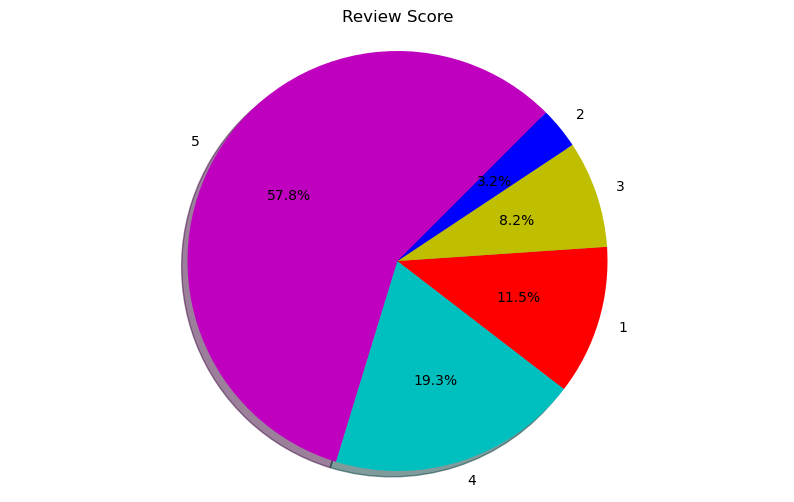

In [86]:
count_review_score = order_reviews_dataset.groupby('review_score')['review_score'].count().sort_values(ascending=False)

plt.figure(figsize=(10,6))

plt.pie(count_review_score ,
        labels =count_review_score.index ,
        autopct ='%1.1f%%' , 
        shadow =True ,
        colors = ['m','c','r','y','b'],
        startangle=45
       )

plt.title('Review Score')
plt.axis('equal')
plt.show()


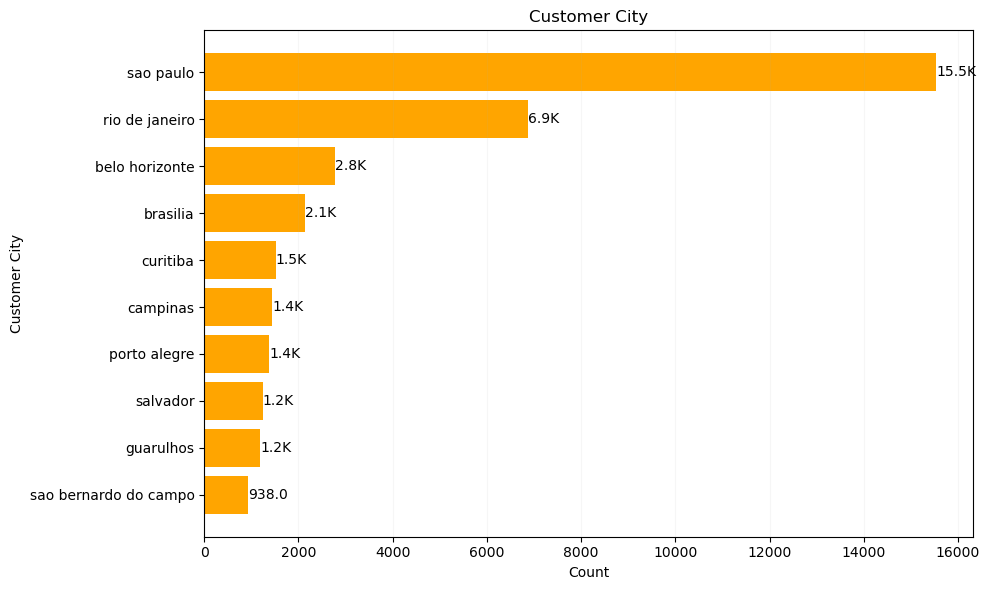

In [87]:
count_customer_city = customers_dataset.groupby('customer_city')['customer_city'].count().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,6))

bars = plt.barh(count_customer_city.index ,
         count_customer_city.values ,
         color = 'orange' 
        )

plt.title('Customer City')
plt.xlabel('Count')
plt.ylabel('Customer City')
plt.grid(axis='x' , alpha =0.1)


def format_num(val):
    if val >=1e6 :
        return f'{val/1e6:.1f}M' ,
    elif val >=1e3 :
        return f'{val/1e3:.1f}K' 
    else:
        return f'{val:.1f}'
        
        

for bar in bars : plt.text(bar.get_width() ,
                           bar.get_y() + bar.get_height() /2 ,
                           format_num(bar.get_width()) ,
                           va='center')

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


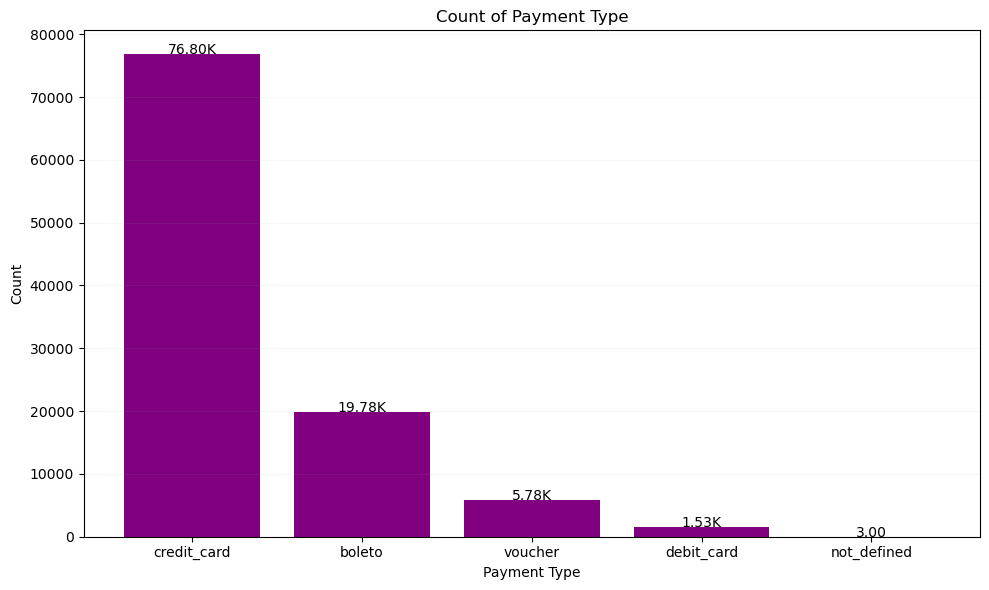

In [88]:
count_payment_type = order_payments_dataset.groupby('payment_type')['payment_type'].count().sort_values(ascending=False)

plt.figure(figsize=(10,6))

bars = plt.bar(count_payment_type .index , count_payment_type.values , color = 'purple')

plt.xlabel('Payment Type')
plt.ylabel('Count')
plt.title('Count of Payment Type')
plt.grid(axis='y' , alpha =0.1)


def format_num(val):
    if val >= 1e6 :
        return f'{val/1e6:.2f}M'
    elif val >= 1e3 :
        return f'{val/1e3:.2f}K'
    else:
        return f'{val:.2f}'


for bar in bars :plt.text(bar.get_x() + bar.get_width() /2 ,
                          bar.get_height(),
                          format_num(bar.get_height()) ,
                          ha='center')

plt.tight_layout()
plt.show()
                          

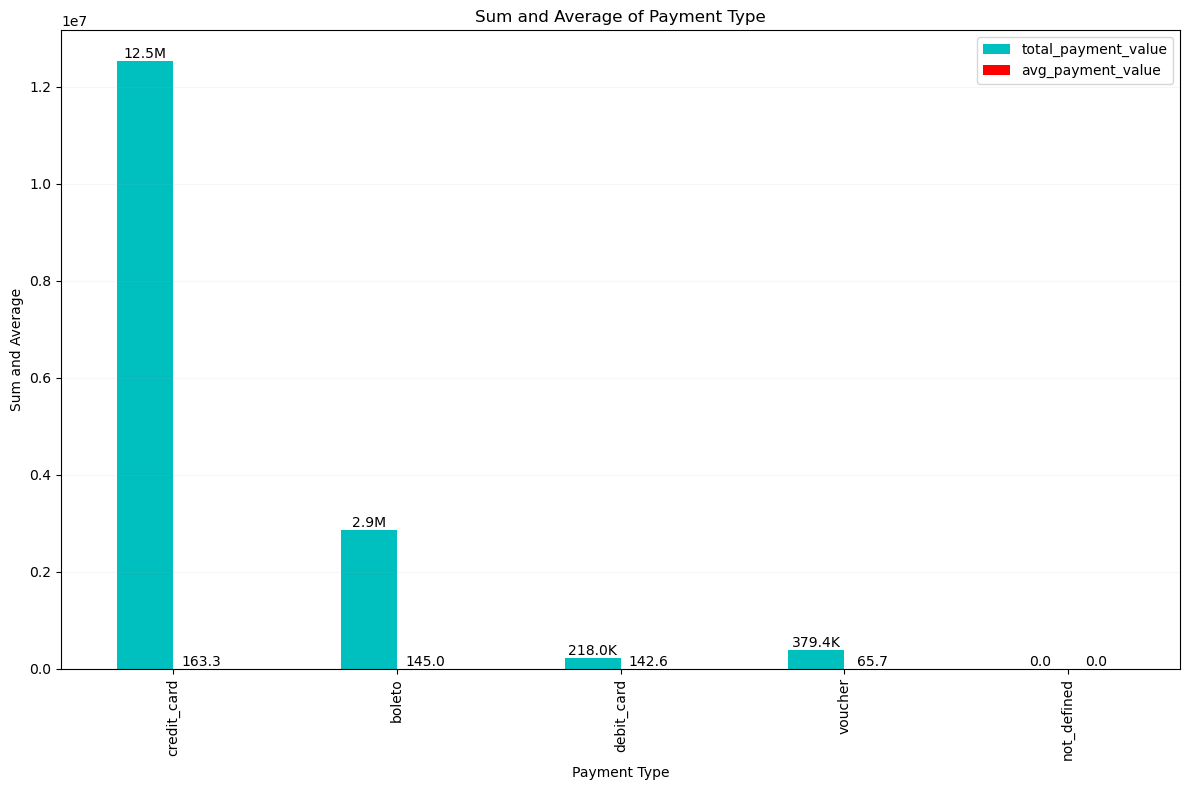

In [89]:
payment_type = order_payments_dataset.groupby('payment_type').agg(
    total_payment_value = ('payment_value' , 'sum') , avg_payment_value = ('payment_value' , 'mean')
).sort_values(by = 'avg_payment_value' ,  ascending=False) 

 
bar_group = payment_type.plot(kind='bar', color = ['c','r'] ,figsize=(12,8))

plt.xlabel('Payment Type')
plt.ylabel('Sum and Average')
plt.title('Sum and Average of Payment Type')
plt.grid(axis='y' , alpha=0.1)


def format_num(val):
    if val >=1e6 :
        return f'{val/1e6:.1f}M'
    elif val >=1e3 :
        return f'{val/1e3:.1f}K' 
    else:
        return f'{val:.1f}'




for container in bar_group .containers: 
    labels=[format_num(v) for v in container.datavalues]
    bar_group.bar_label( container , labels=labels)

plt.tight_layout()
plt.show()
    

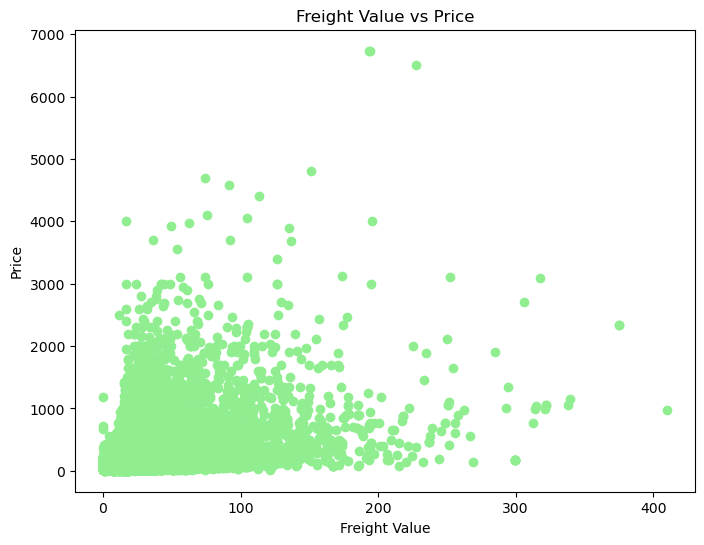

In [90]:
plt.figure(figsize=(8,6))

scatter = plt.scatter(order_items_dataset['freight_value'] , order_items_dataset['price'] , color = 'lightgreen')

plt.xlabel('Freight Value')
plt.ylabel('Price')
plt.title('Freight Value vs Price')

plt.show()

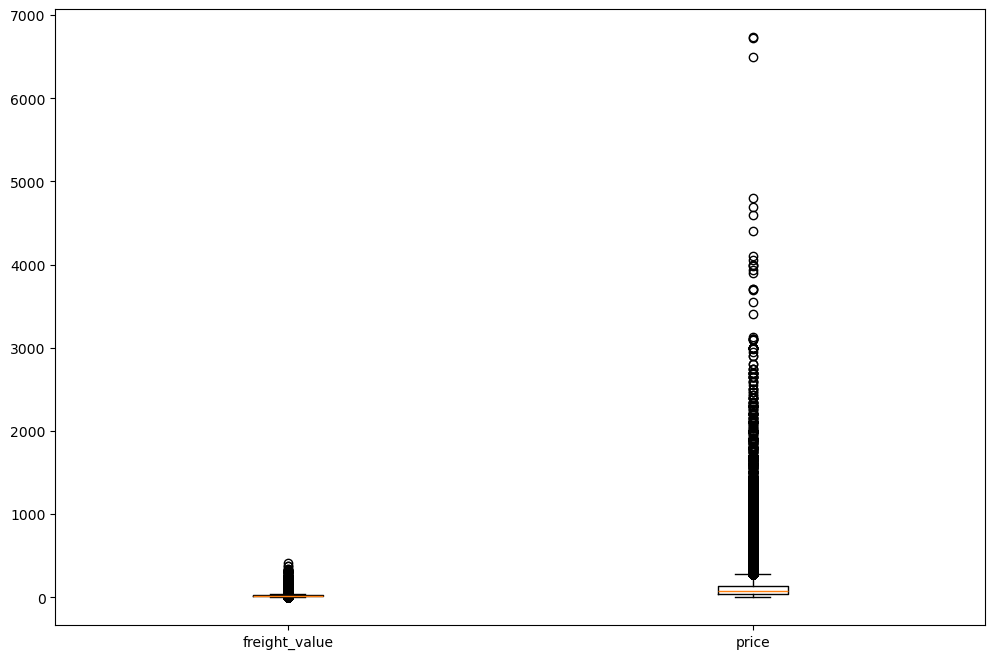

In [118]:
plt.figure(figsize=(12,8))
boxplot = plt.boxplot([order_items_dataset['freight_value'] , order_items_dataset['price']] )
plt.xticks([1,2] , ['freight_value' , 'price'])


plt.show()

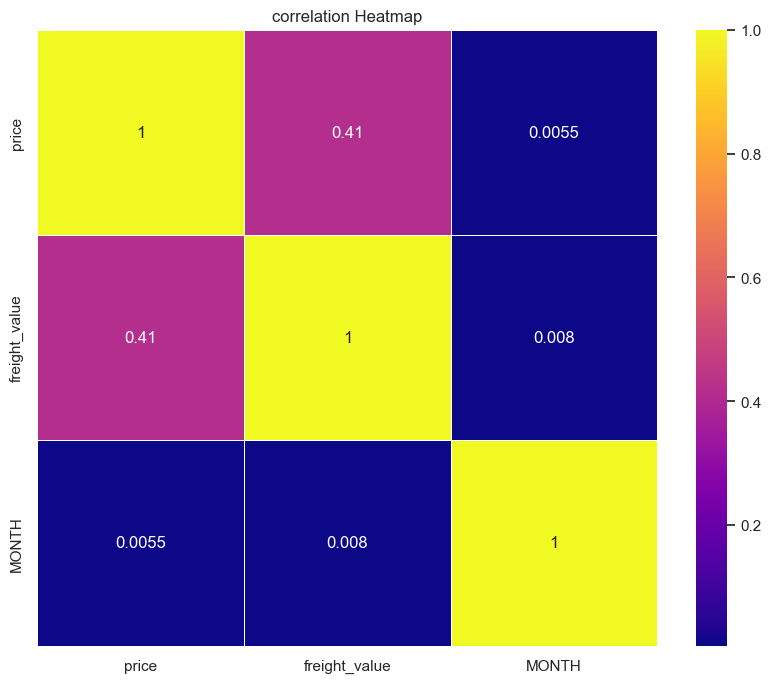

In [151]:
corr =order_items_dataset[['price','freight_value','MONTH']].corr()

plt.figure(figsize=(10,8))

heatmap = sns.heatmap(corr , 
            annot = True , 
            cmap='plasma' , 
            linewidth=0.5)

plt.title('correlation Heatmap')
plt.show()

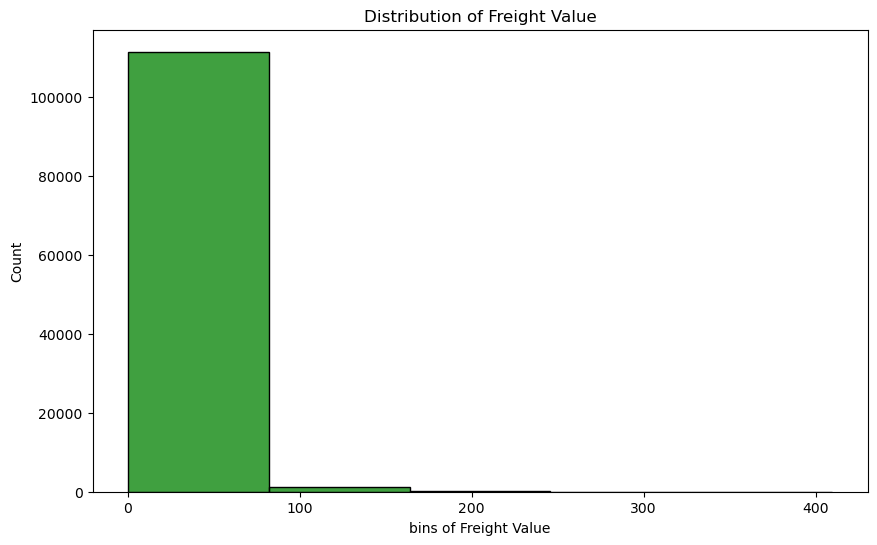

In [103]:
plt.figure(figsize=(10,6))
sns.histplot(order_items_dataset['freight_value'] ,
             bins=5 ,
             color = 'green',
             edgecolor='black')
plt.xlabel('bins of Freight Value')
plt.ylabel('Count')
plt.title('Distribution of Freight Value')

plt.show()

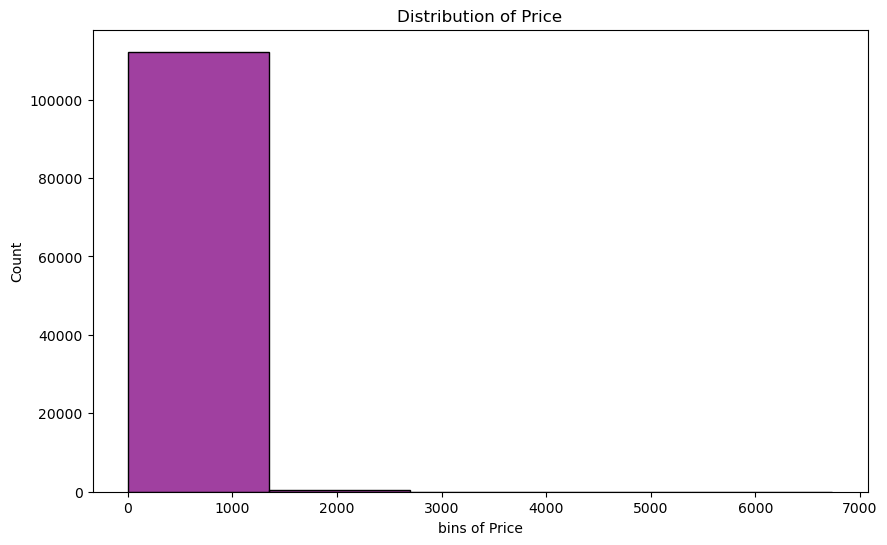

In [104]:
plt.figure(figsize=(10,6))
sns.histplot(order_items_dataset['price'] ,
             bins=5 ,
             color = 'purple',
             edgecolor='black')
plt.xlabel('bins of Price')
plt.ylabel('Count')
plt.title('Distribution of Price')

plt.show()

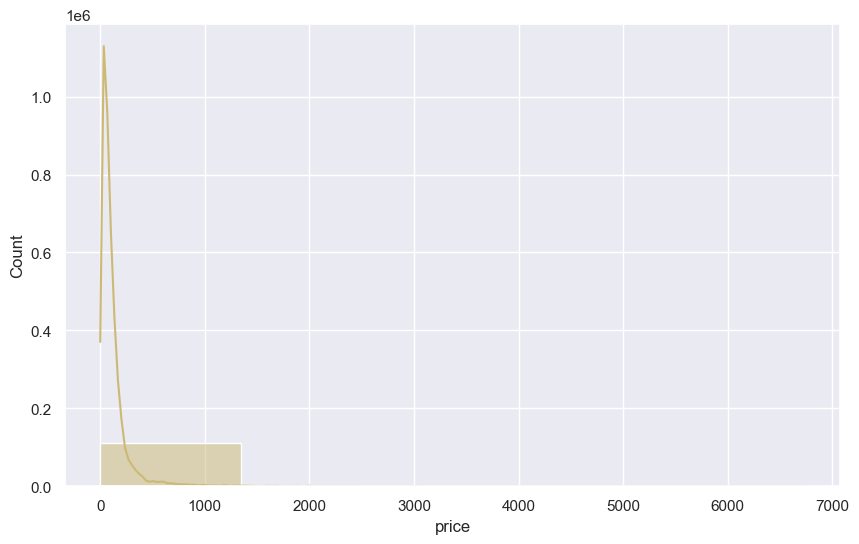

In [122]:
plt.figure(figsize=(10,6))
sns.histplot(order_items_dataset['price'] ,
             bins=5 ,
             kde=True ,
             color = 'y')
sns.set_theme(style="darkgrid")
             
plt.show()

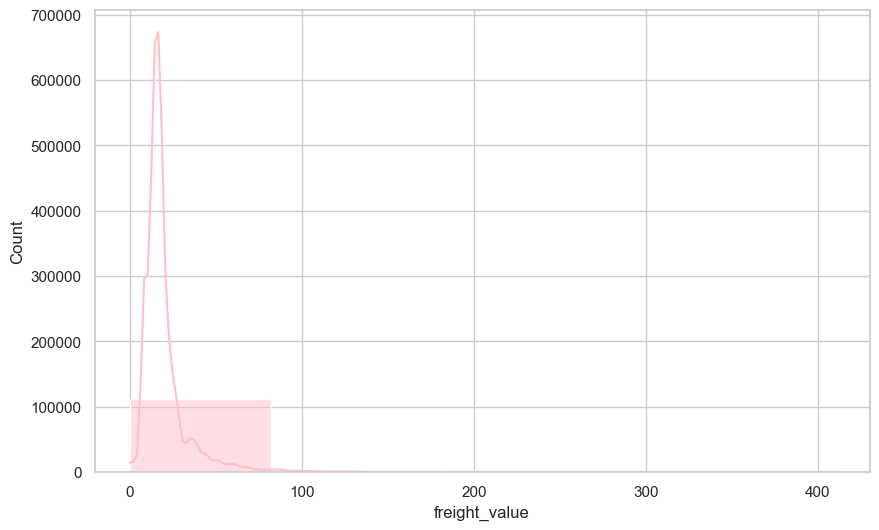

In [135]:
plt.figure(figsize=(10,6))
sns.histplot(order_items_dataset['freight_value'] ,
             bins=5 ,
             kde=True ,
             color = 'pink')
sns.set_theme(style="whitegrid")             
plt.show()

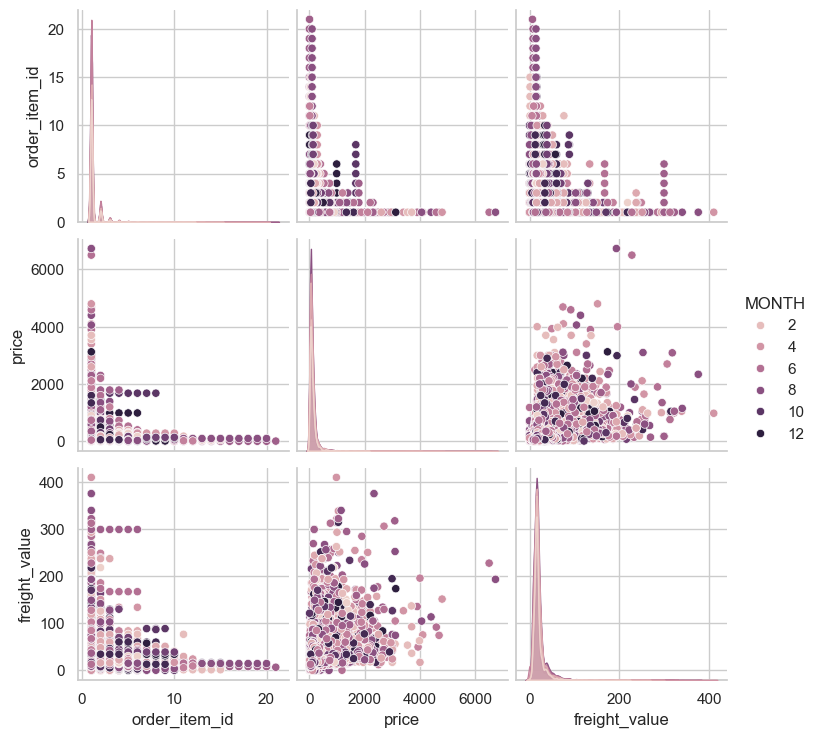

In [160]:
sns.pairplot(order_items_dataset , hue='MONTH')
plt.show()

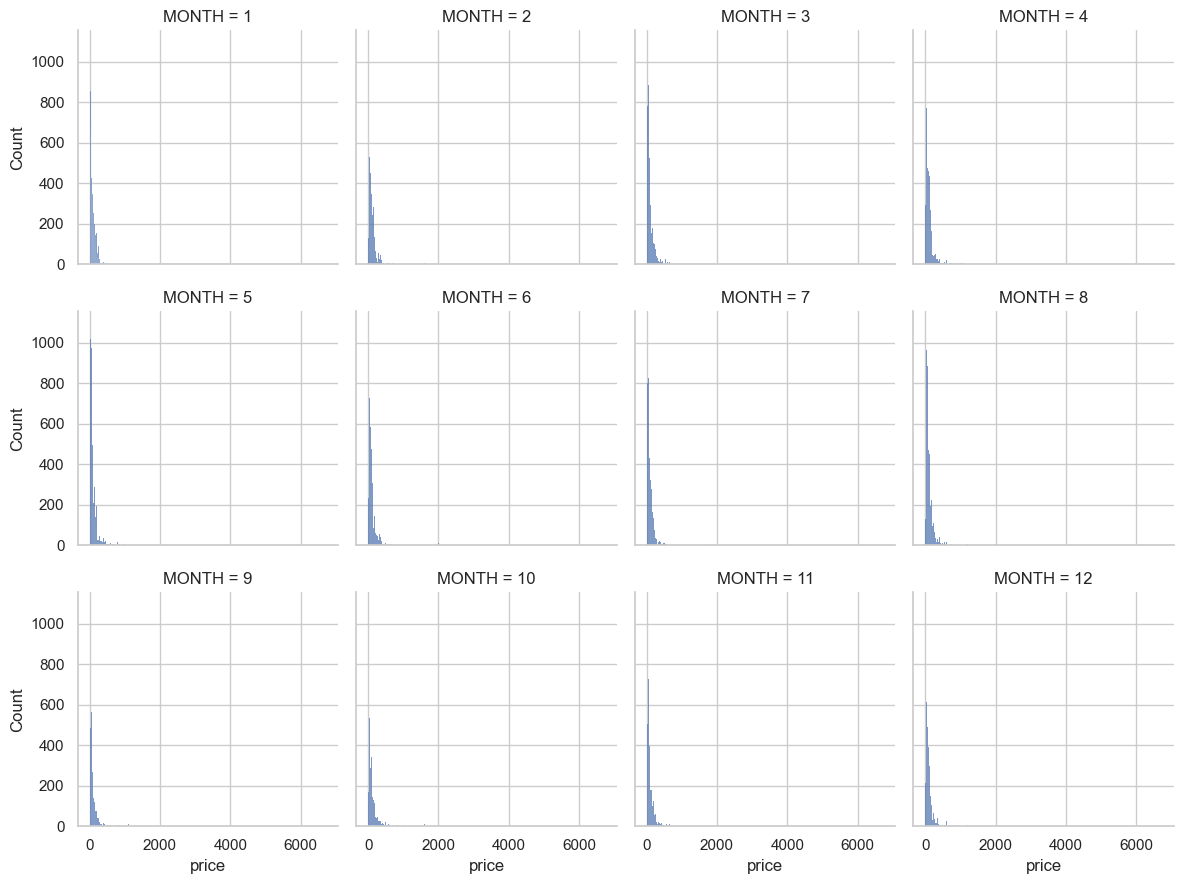

In [157]:
g = sns.FacetGrid(order_items_dataset ,
                  col = 'MONTH' , col_wrap=4)
g.map(sns.histplot, "price" )      
plt.show()

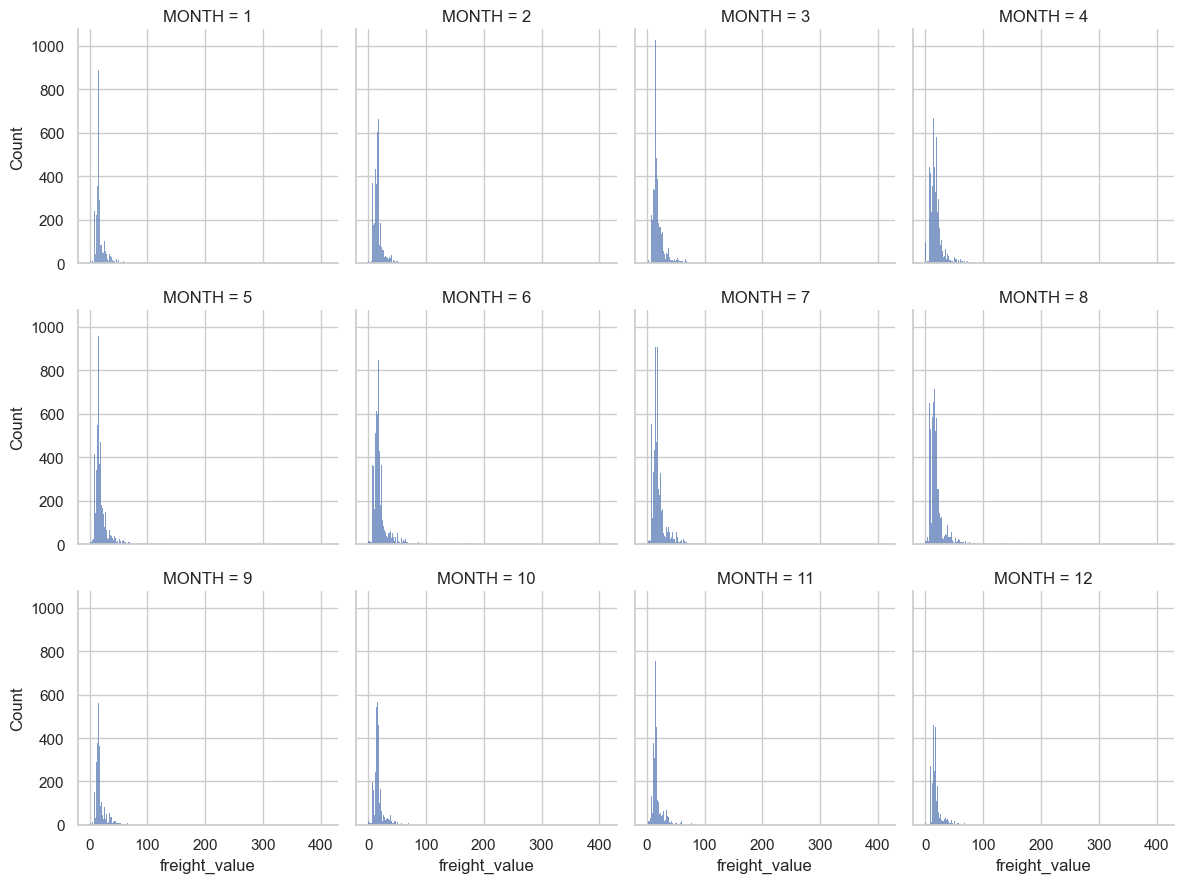

In [158]:
g = sns.FacetGrid(order_items_dataset ,
                  col = 'MONTH' , col_wrap=4)
g.map(sns.histplot, "freight_value" )      
plt.show()